# Tech Challenge Fase 2 — Otimização de rotas médicas

Este notebook apresenta a representação, os operadores, a conferência das restrições e a comparação experimental. Os pontos de entrega são fictícios e os tempos são estimados sobre ruas reais. A função objetivo representa uma preferência de planejamento; seus pesos não foram validados clinicamente.

O núcleo está no pacote `rotas_medicas`, também utilizado pela API e pela CLI. Para reproduzir a análise completa, executar antes `tc2 experimentos` e `python scripts/gerar_analise.py`. As células abaixo executam novamente um exemplo e analisam os registros completos, com a origem de cada resultado explícita.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from rotas_medicas.config import PROJECT_ROOT as ROOT
from rotas_medicas.storage import load_scenario, load_solution, canonical_hash
from rotas_medicas.verification import verify_solution
results = pd.read_csv(ROOT / "outputs/experiments/results.csv")
analysis = json.loads((ROOT / "outputs/analysis/summary.json").read_text(encoding="utf-8"))
selected = analysis["selected"]
print("Configuração escolhida apenas no desenvolvimento:", selected)
print("Execuções tabuladas:", len(results))
print("SHA-256 da tabela:", analysis["results_sha256"])

Configuração escolhida apenas no desenvolvimento: pop80_mut10
Execuções tabuladas: 278
SHA-256 da tabela: 914e8a0d045451af9f39f01570c367764deabd5c646c298940b3d7c1622852cf


## 1. Dados e problema

Cada veículo sai do mesmo depósito com toda a carga da sua rota e retorna ao final. As entregas devem ser visitadas exatamente uma vez. A carga inicial não pode ultrapassar a capacidade e a distância completa deve respeitar a autonomia. Dois pedidos no mesmo endereço continuam sendo duas entregas distintas.

A distância é medida em metros nos dados médicos. A duração é medida em segundos e pode ser assimétrica, pois as ruas têm sentidos de circulação. A carga é expressa em kg. Cada par da matriz conserva a geometria do mesmo percurso usado para calcular distância e tempo.

In [2]:
scenario = load_scenario(ROOT / "data/scenarios/sp_evaluation_30.json")
display(pd.DataFrame([d.model_dump() for d in scenario.deliveries]).drop(columns=["x","y"]).head(10))
display(pd.DataFrame([v.model_dump() for v in scenario.vehicles]))
print("Distribuição das prioridades:", pd.Series([d.priority.value for d in scenario.deliveries]).value_counts().to_dict())
print("Matriz assimétrica:", any(abs(scenario.distance[i][j]-scenario.distance[j][i])>1e-6 for i in range(31) for j in range(31)))

,id,name,load,priority,service_s
0,ENT_001,Unidade simulada 001,6.0,regular,300.0
1,ENT_002,Unidade simulada 002,8.0,regular,180.0
2,ENT_003,Unidade simulada 003,5.0,critica,180.0
3,ENT_004,Unidade simulada 004,5.0,urgente,300.0
4,ENT_005,Unidade simulada 005,2.0,critica,420.0
5,ENT_006,Unidade simulada 006,6.0,regular,180.0
6,ENT_007,Unidade simulada 007,10.0,regular,300.0
7,ENT_008,Unidade simulada 008,3.0,regular,180.0
8,ENT_009,Unidade simulada 009,4.0,urgente,420.0
9,ENT_010,Unidade simulada 010,6.0,regular,180.0


,id,capacity,max_distance
0,VEI_01,74.0,50000.0
1,VEI_02,74.0,50000.0
2,VEI_03,74.0,50000.0


Distribuição das prioridades: {'regular': 17, 'urgente': 7, 'critica': 6}
Matriz assimétrica: True


## 2. Objetivo e resposta conhecida

Entre soluções viáveis, minimizamos **J = distância em km + α × soma dos minutos de chegada ponderados**. Usamos α = 0,05 km/min e pesos 1, 3 e 10 para prioridades regular, urgente e crítica. Cada veículo tem um relógio próprio, iniciado na saída comum. O atendimento de uma parada atrasa as seguintes.

Antes de interpretar cenários grandes, conferimos um caso pequeno. Num triângulo com três lados de 1 km e viagens de um minuto, visitar primeiro a entrega crítica produz J = 3 + 0,05 × (10 × 1 + 1 × 2) = 3,6. A ordem inversa produz 4,05. O oráculo abaixo enumera as alternativas sem utilizar a avaliação do genético.

In [3]:
from rotas_medicas.domain import Scenario,Location,Delivery,Vehicle,GAConfig
from rotas_medicas.oracle import exact_small
tiny = Scenario(id="notebook_oracle",description="Caso independente de duas entregas",coordinates="cartesian",
    depot=Location(id="D",name="Depósito",x=0,y=0),
    deliveries=[Delivery(id="A",name="Crítica",x=1,y=0,load=1,priority="critica",service_s=0),Delivery(id="B",name="Regular",x=0,y=1,load=1,service_s=0)],
    vehicles=[Vehicle(id="V1",capacity=2,max_distance=3000)],
    distance=[[0,1000,1000],[1000,0,1000],[1000,1000,0]],duration_s=[[0,60,60],[60,0,60],[60,60,0]])
oracle = exact_small(tiny)
display(oracle)
assert abs(oracle["objective"]-3.6)<1e-9

{'feasible': True,
 'objective': 3.6,
 'routes': [[1, 2]],
 'examined': 2,
 'method': 'independent_exhaustive_enumeration'}

## 3. Representação e evolução da base FIAP

A cópia original está preservada no commit `d236a2ae6a08fefdb8ee9f1ca3f8201223a92da3`. A base usa coordenadas como genes e chama OX com o mesmo pai; isso reduz a recombinação e não conserva a identidade de pedidos em coordenadas repetidas. A nova representação usa identificadores únicos, convertidos em índices internos positivos, com separadores negativos para dividir a frota.

A seleção usa torneio de três indivíduos, crossover OX com probabilidade 0,90, mutação por troca ou inversão e dois elites. A reparação determinística realoca ou troca entregas para reduzir violações. Primeiro se comparam as restrições; só depois, o objetivo. Um candidato curto e inválido não supera uma solução viável.

In [4]:
import random
from rotas_medicas.genetic import encode,decode,order_crossover,mutate,solve_genetic
parent1 = encode([[1,2],[3,4]])
parent2 = encode([[4,2,1],[3]])
rng = random.Random(42)
child = mutate(order_crossover(parent1,parent2,rng),rng,1.0)
print("Pais:",parent1,parent2)
print("Filho:",child,"Rotas:",decode(child,2))
assert sorted(child)==sorted(parent1)

Pais: (1, 2, -1, 3, 4) (4, 2, 1, -1, 3)
Filho: (1, -1, 2, 3, 4) Rotas: [[1], [2, 3, 4]]


## 4. Execução e certificação

Este exemplo é uma execução nova do núcleo. O teto de 20 mil chamadas de fitness inclui a inicialização e os candidatos avaliados pela reparação. Também se limitam as tentativas da população para encerrar a repetição de indivíduos já conhecidos. A melhor solução viável observada é preservada quando o orçamento termina. Custos de inserção de rotas parciais são registrados separadamente; a certificação final não é uma avaliação de busca.

In [5]:
small = load_scenario(ROOT / "data/scenarios/sp_evaluation_12.json")
demo = solve_genetic(small,GAConfig(population_size=80,mutation_probability=.10,max_evaluations=20000,seed=42))
certificate = verify_solution(small,demo)
assert demo.status=="feasible" and certificate.valid
display(demo.metrics.model_dump())
print("Fitness:",demo.metadata["evaluations"],"Tentativas:",demo.metadata["candidate_attempts"],"Término:",demo.metadata["termination"])
saved = load_solution(ROOT / "outputs/experiments/runs/sp_evaluation_12" / "genetic_pop80_mut10_42.json")
assert abs(saved.metrics.objective-demo.metrics.objective)<1e-9
adulterated = demo.model_copy(deep=True)
adulterated.routes[0].stops.pop()
print("Adulteração rejeitada:",not verify_solution(small,adulterated).valid)

{'total_distance': 40459.15593520023,
 'total_duration_s': 6768.4665104542655,
 'weighted_arrival_s': 23543.938893187737,
 'critical_arrival_mean_s': 409.5988918648294,
 'vehicles_used': 2,
 'deliveries_served': 12,
 'objective': 60.07910501285667}

Fitness: 10377 Tentativas: 20000 Término: candidate_attempt_budget
Adulteração rejeitada: True


## 5. Desenho experimental

Três configurações combinam populações 80/160/240 com mutações 0,10/0,20/0,30. Cada configuração é avaliada com dez sementes nos cenários finais. O ajuste usa apenas três cenários de desenvolvimento, com três sementes por configuração. O resultado da seleção é salvo antes da avaliação final.

O guloso escolhe a melhor construção entre prioridade/proximidade, carga decrescente e proximidade. OR-Tools utiliza cinco segundos e as mesmas restrições. O GA usa limites de avaliações, tentativas e tempo. Esses orçamentos não são equivalentes: registramos os tempos e evitamos atribuir toda diferença ao algoritmo. Há atividades locais em paralelo durante a execução; os tempos não são um benchmark de hardware isolado.

In [6]:
development = json.loads((ROOT / "outputs/experiments/selection.json").read_text(encoding="utf-8"))
display(pd.DataFrame.from_dict(development["mean_ratios"],orient="index",columns=["razão média GA/guloso em desenvolvimento"]))
medical = results[results.scenario.isin(["sp_evaluation_12","sp_evaluation_30","sp_evaluation_60"])]
display(medical.groupby(["scenario","algorithm","configuration"]).agg(execuções=("status","size"),J_médio=("objective","mean"),J_desvio=("objective","std"),J_mínimo=("objective","min"),J_máximo=("objective","max"),tempo_médio_s=("elapsed_s","mean")))

,razão média GA/guloso em desenvolvimento
pop80_mut10,0.995440
pop160_mut20,0.995619
pop240_mut30,0.997466


execuções     J_médio  J_desvio  \
scenario         algorithm configuration                                    
sp_evaluation_12 genetic   pop160_mut20          10   60.079105  0.000000   
                           pop240_mut30          10   60.079105  0.000000   
                           pop80_mut10           10   60.079105  0.000000   
                 greedy    baseline               1   60.856810       NaN   
                 ortools   baseline               1   60.079105       NaN   
sp_evaluation_30 genetic   pop160_mut20          10  181.929431  0.000000   
                           pop240_mut30          10  181.929431  0.000000   
                           pop80_mut10           10  181.243854  0.687837   
                 greedy    baseline               1  181.929431       NaN   
                 ortools   baseline               1  175.839693       NaN   
sp_evaluation_60 genetic   pop160_mut20          10  363.389448  0.000000   
                           pop240_mut30          10  363.389448  0.000000   
                           pop80_mut10           10  363.389448  0.000000   
                 greedy    baseline               1  363.389448       NaN   
                 ortools   baseline               1  339.971368       NaN   

                                            J_mínimo    J_máximo  \
scenario         algorithm configuration                           
sp_evaluation_12 genetic   pop160_mut20    60.079105   60.079105   
                           pop240_mut30    60.079105   60.079105   
                           pop80_mut10     60.079105   60.079105   
                 greedy    baseline        60.856810   60.856810   
                 ortools   baseline        60.079105   60.079105   
sp_evaluation_30 genetic   pop160_mut20   181.929431  181.929431   
                           pop240_mut30   181.929431  181.929431   
                           pop80_mut10    179.804424  181.929431   
                 greedy    baseline       181.929431  181.929431   
                 ortools   baseline       175.839693  175.839693   
sp_evaluation_60 genetic   pop160_mut20   363.389448  363.389448   
                           pop240_mut30   363.389448  363.389448   
                           pop80_mut10    363.389448  363.389448   
                 greedy    baseline       363.389448  363.389448   
                 ortools   baseline       339.971368  339.971368   

                                          tempo_médio_s  
scenario         algorithm configuration                 
sp_evaluation_12 genetic   pop160_mut20        0.472858  
                           pop240_mut30        0.502245  
                           pop80_mut10         0.387905  
                 greedy    baseline            0.001081  
                 ortools   baseline            5.006801  
sp_evaluation_30 genetic   pop160_mut20        0.340140  
                           pop240_mut30        0.327289  
                           pop80_mut10         0.394870  
                 greedy    baseline            0.006883  
                 ortools   baseline            5.001019  
sp_evaluation_60 genetic   pop160_mut20        0.602883  
                           pop240_mut30        0.599618  
                           pop80_mut10         0.600227  
                 greedy    baseline            0.031134  
                 ortools   baseline            5.003122

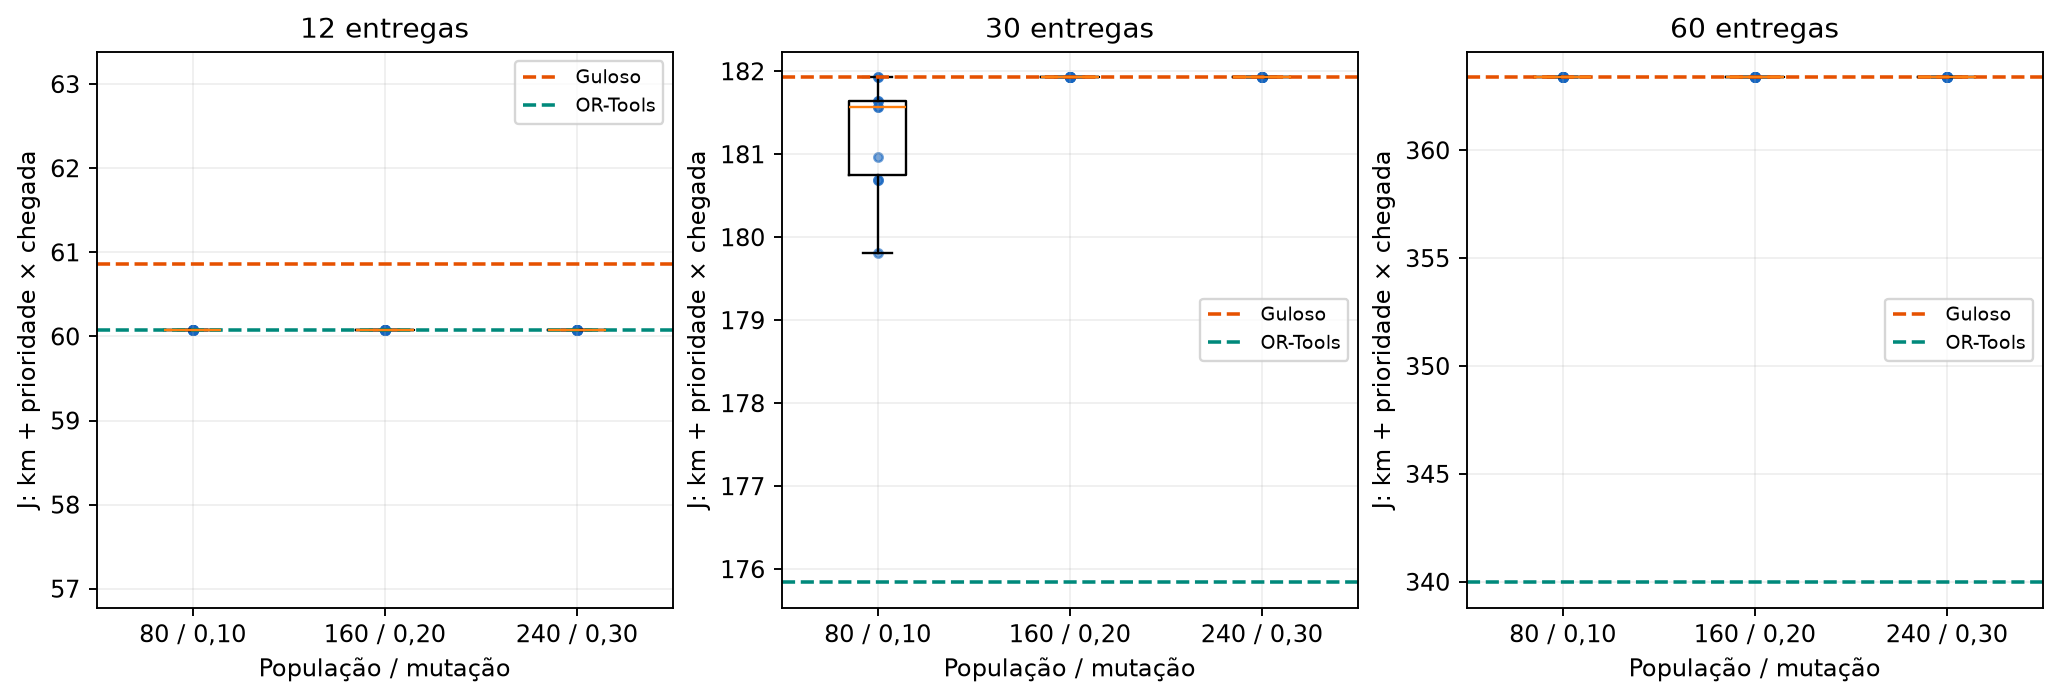

In [7]:
display(Image(filename=str(ROOT / "outputs/figures/medical_objective.png")))

Os pontos mantêm a dispersão entre sementes. A comparação de J considera simultaneamente distância e chegada ponderada. Mesmo quando duas soluções têm quilômetros próximos, uma pode chegar mais cedo às entregas prioritárias. O gráfico preserva situações em que o GA não melhora o guloso ou fica atrás de OR-Tools.

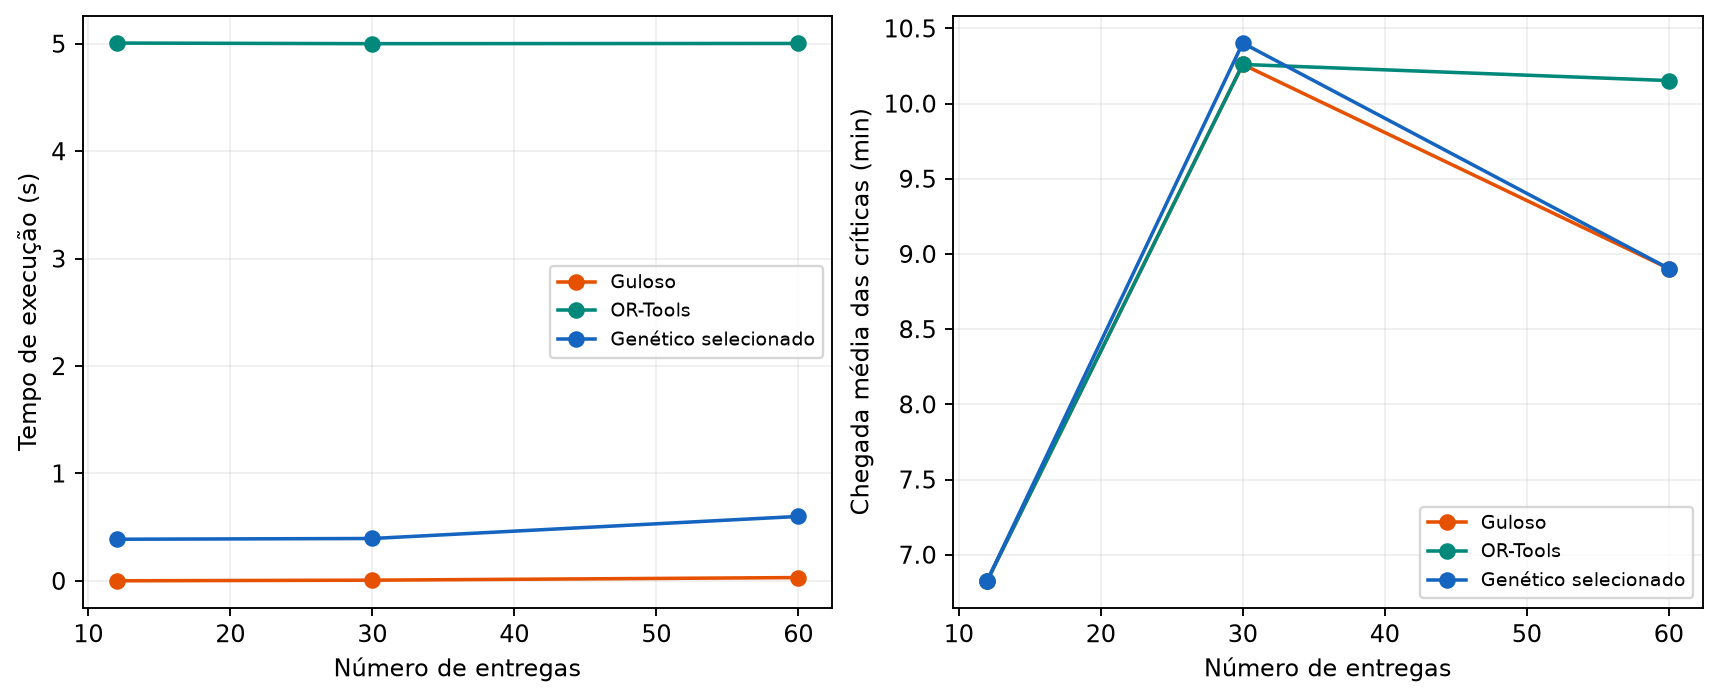

In [8]:
display(Image(filename=str(ROOT / "outputs/figures/runtime_critical.png")))

## 6. Benchmarks e referência original

Na CVRPLIB, mantemos as capacidades, a frota e o arredondamento EUC_2D original: `floor(distância + 0,5)`. Os custos de referência são 784, 1167 e 1763. Nessas instâncias, o objetivo é somente a distância original; não adicionamos tempo ou prioridade. O gap é 100 × (custo / ótimo publicado − 1).

A base FIAP é comparada apenas no TSP compatível de 15 pontos. Sua reprodução conserva o crossover com o mesmo pai e um elite. Não comparamos sua distância de tela diretamente com quilômetros das rotas hospitalares.

gap_médio_pct  gap_mínimo_pct  \
scenario  algorithm configuration                                  
A-n32-k5  genetic   pop160_mut20       40.369898       35.714286   
                    pop240_mut30       40.369898       35.714286   
                    pop80_mut10        40.369898       35.714286   
          greedy    baseline           42.474490       42.474490   
          ortools   baseline            0.000000        0.000000   
A-n54-k7  genetic   pop160_mut20       31.962296       28.877464   
                    pop240_mut30       31.962296       28.877464   
                    pop80_mut10        31.962296       28.877464   
          greedy    baseline           32.305056       32.305056   
          ortools   baseline            6.341045        6.341045   
A-n80-k10 genetic   pop160_mut20       36.018151       36.018151   
                    pop240_mut30       36.018151       36.018151   
                    pop80_mut10        36.018151       36.018151   
          greedy    baseline           36.018151       36.018151   
          ortools   baseline            2.665910        2.665910   

                                   gap_máximo_pct  viáveis  
scenario  algorithm configuration                           
A-n32-k5  genetic   pop160_mut20        42.474490       10  
                    pop240_mut30        42.474490       10  
                    pop80_mut10         42.474490       10  
          greedy    baseline            42.474490        1  
          ortools   baseline             0.000000        1  
A-n54-k7  genetic   pop160_mut20        32.305056       10  
                    pop240_mut30        32.305056       10  
                    pop80_mut10         32.305056       10  
          greedy    baseline            32.305056        1  
          ortools   baseline             6.341045        1  
A-n80-k10 genetic   pop160_mut20        36.018151       10  
                    pop240_mut30        36.018151       10  
                    pop80_mut10         36.018151       10  
          greedy    baseline            36.018151        1  
          ortools   baseline             2.665910        1

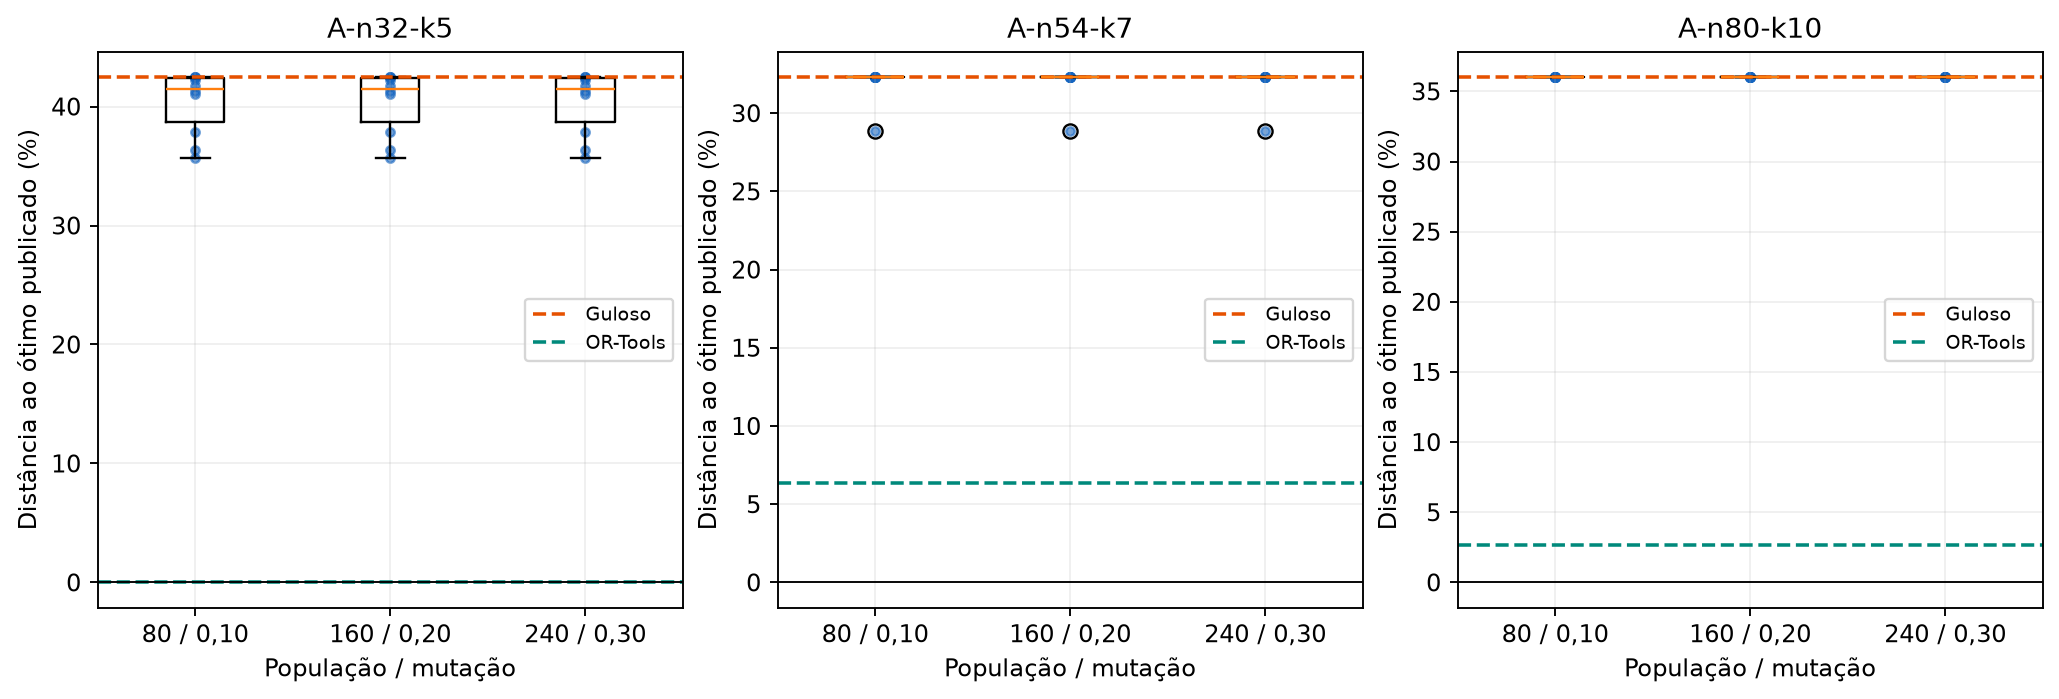

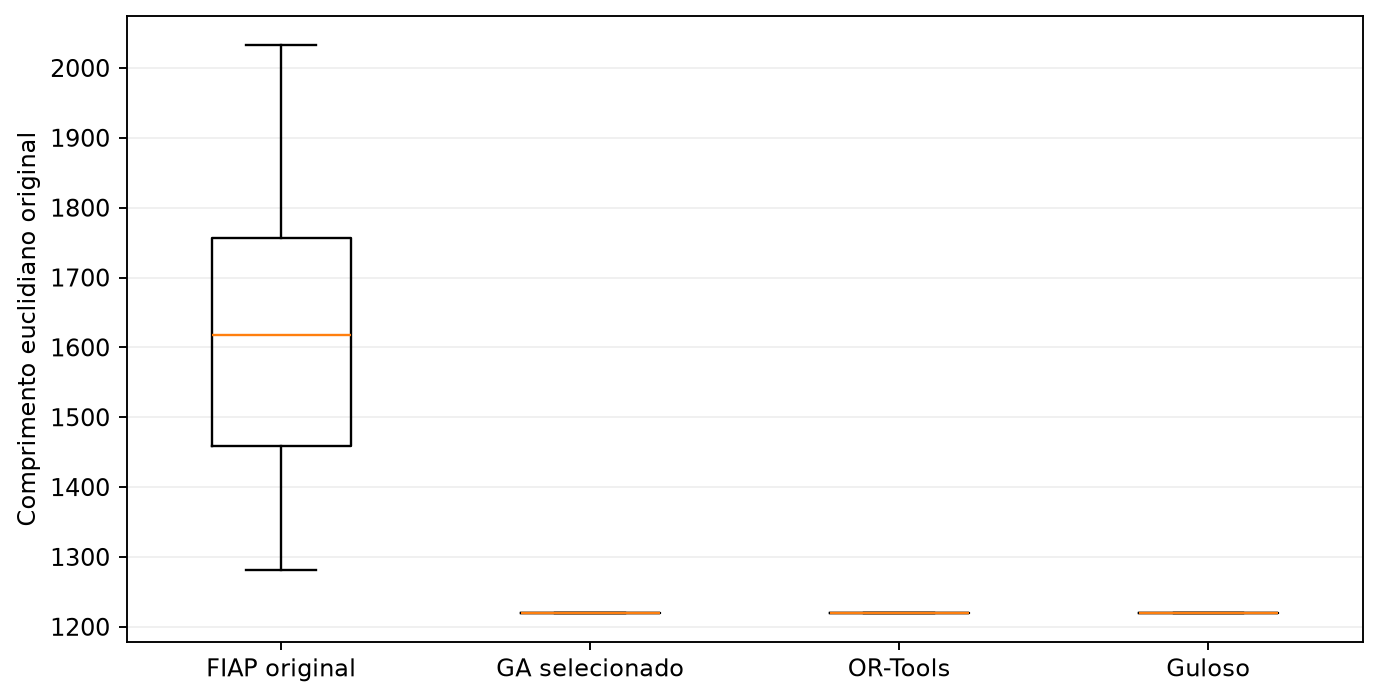

In [9]:
bench = results[results.scenario.str.startswith("A-n")]
display(bench.groupby(["scenario","algorithm","configuration"]).agg(gap_médio_pct=("gap_percent","mean"),gap_mínimo_pct=("gap_percent","min"),gap_máximo_pct=("gap_percent","max"),viáveis=("status",lambda s:(s=="feasible").sum())))
display(Image(filename=str(ROOT / "outputs/figures/benchmark_gap.png")))
display(Image(filename=str(ROOT / "outputs/figures/fiap_tsp.png")))

## 7. Convergência, sensibilidade e limitações

A reparação é parte do custo computacional da busca. Em problemas maiores, ela pode consumir todo o orçamento durante a inicialização. Um ponto isolado no gráfico indica essa interrupção e não comprova evolução ao longo de gerações. A dificuldade sugere uma reparação incremental e uma construção inicial mais eficiente como trabalhos futuros.

A análise de prioridade varia o coeficiente em um cenário de 30 entregas e uma semente. É uma exploração da premissa, sem alegação causal nem definição de pesos clínicos. A autonomia corresponde a distância, sem modelo de combustível ou bateria dependente da carga.

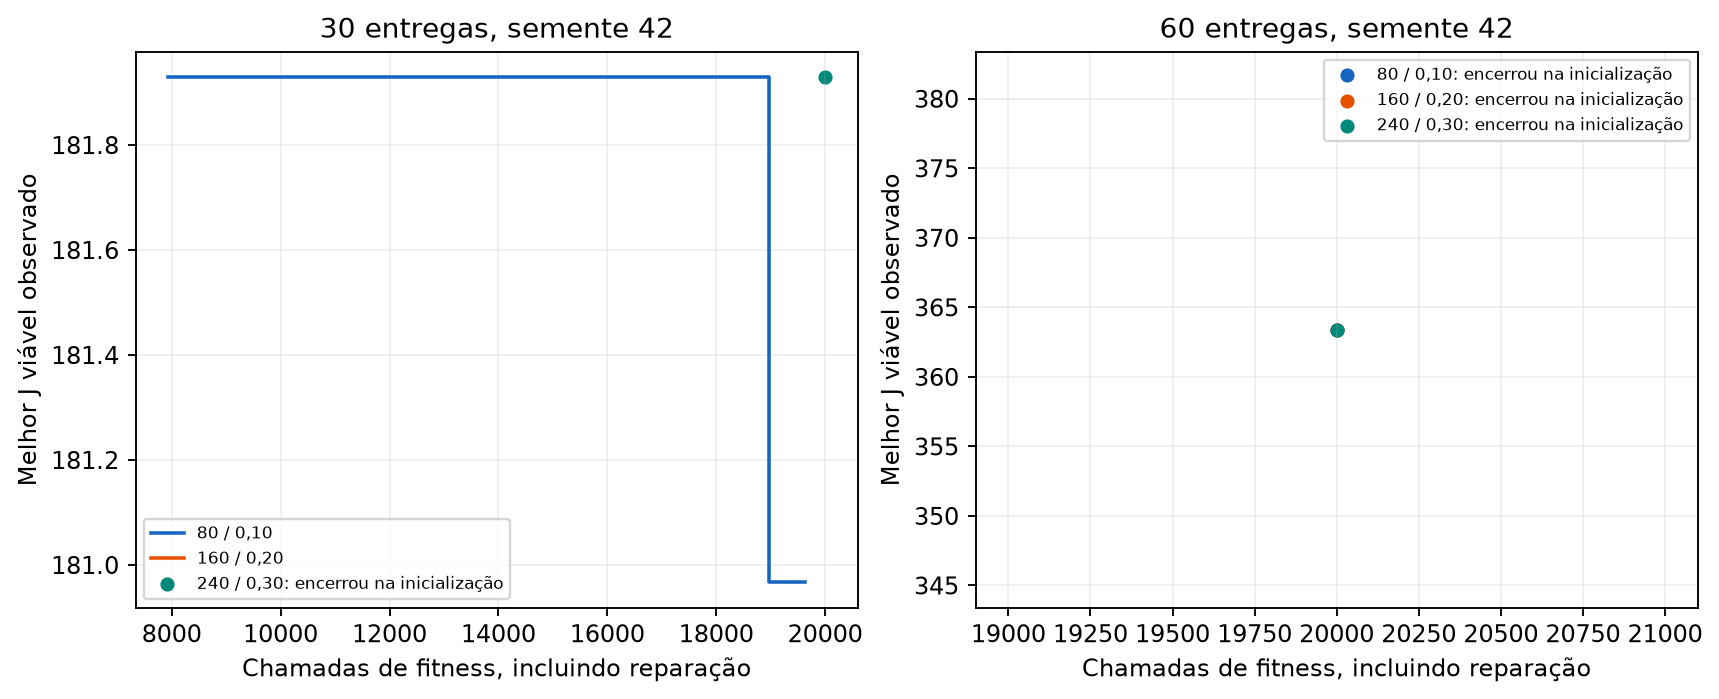

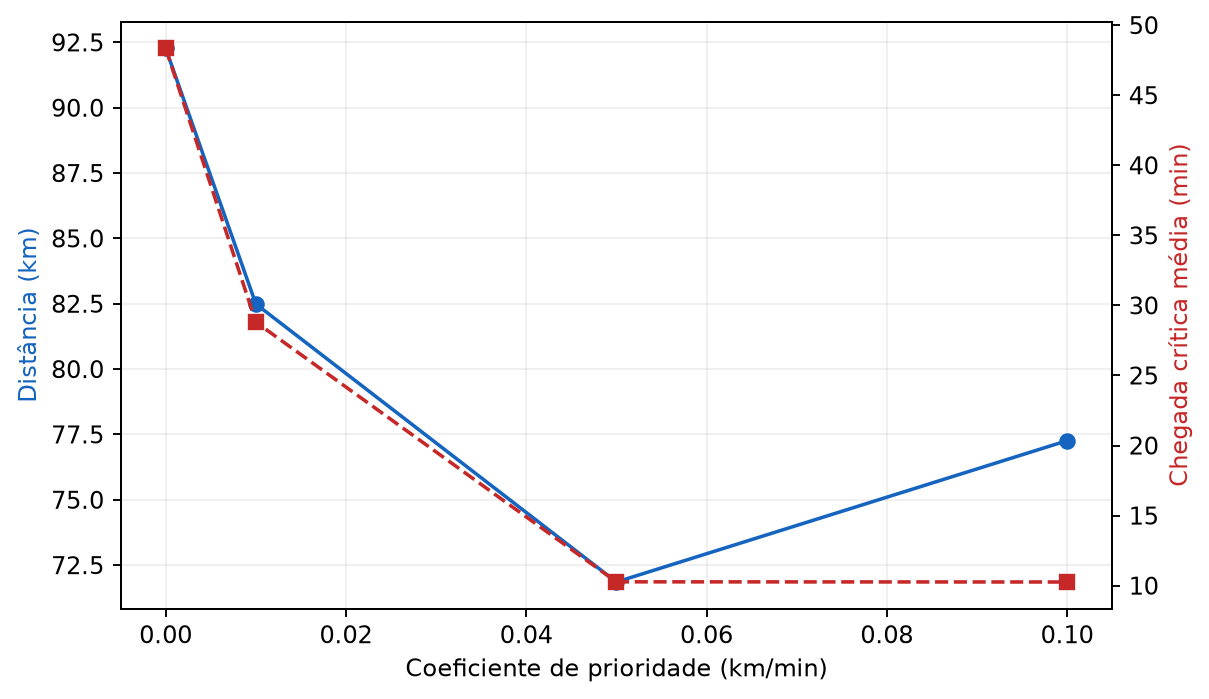

,scenario,distance,critical_arrival_mean_s,objective,termination
261,sp_sensitivity_0,92270.368050,2900.474482,92.270368,evaluation_budget
262,sp_sensitivity_0_01,82491.954120,1728.428937,117.204820,evaluation_budget
263,sp_sensitivity_0_05,71855.364388,616.377048,180.966788,evaluation_budget
264,sp_sensitivity_0_1,77262.972781,615.630997,301.534218,evaluation_budget


Términos do GA: {'evaluation_budget': 190, 'candidate_attempt_budget': 60}


In [10]:
display(Image(filename=str(ROOT / "outputs/figures/convergence.png")))
display(Image(filename=str(ROOT / "outputs/figures/priority_sensitivity.png")))
display(results[results.scenario.str.startswith("sp_sensitivity_")][["scenario","distance","critical_arrival_mean_s","objective","termination"]])
print("Términos do GA:",analysis["termination_counts"])

## 8. Reprodução e conclusão

As soluções finais são certificadas independentemente. Uma busca sem solução viável retorna diagnóstico e não libera rotas. As tabelas, os gráficos e o relatório derivam dos mesmos registros, identificados por hash. O comando `tc2 validar --perfil entrega` reúne as verificações e mantém pendências externas explícitas.

O valor acadêmico do experimento está na formulação, na extensão da base, na comparação controlada e na análise dos limites. Superar todos os concorrentes não é condição de conclusão. Estes resultados não validam uso clínico ou operacional real.

Fontes: [FIAP](https://github.com/FIAP/genetic_algorithm_tsp), [CVRPLIB](https://galgos.inf.puc-rio.br/cvrplib/en/instances), [OSMnx](https://osmnx.readthedocs.io/en/stable/user-reference.html), [OR-Tools](https://developers.google.com/optimization/routing/vrp).